In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 12.1 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
model = YOLO("/content/best.pt")

In [ ]:
pred = model.predict("/content/no_plate_image.png")


image 1/1 /content/no_plate_image.png: 448x640 1 License-Plate, 10.4ms
Speed: 198.0ms preprocess, 10.4ms inference, 44.0ms postprocess per image at shape (1, 3, 448, 640)


array([[[243, 193, 165],
        [243, 196, 169],
        [232, 189, 168],
        ...,
        [ 95,  94, 103],
        [129, 128, 137],
        [107, 107, 113]],

       [[239, 194, 167],
        [228, 187, 162],
        [214, 177, 157],
        ...,
        [127, 126, 135],
        [124, 123, 132],
        [135, 135, 141]],

       [[225, 193, 170],
        [182, 153, 132],
        [149, 123, 106],
        ...,
        [130, 129, 138],
        [ 98,  97, 106],
        [ 99,  99, 105]],

       ...,

       [[ 76,  70,  71],
        [ 95,  89,  90],
        [ 84,  78,  79],
        ...,
        [108, 101,  98],
        [ 90,  83,  80],
        [ 95,  88,  85]],

       [[ 73,  67,  68],
        [ 87,  81,  82],
        [ 78,  72,  73],
        ...,
        [109, 101, 101],
        [ 91,  83,  83],
        [ 98,  90,  90]],

       [[ 85,  79,  80],
        [ 93,  87,  88],
        [ 84,  78,  79],
        ...,
        [110, 102, 102],
        [ 93,  85,  85],
        [ 98,  90,  90]]], dtype=uint8)
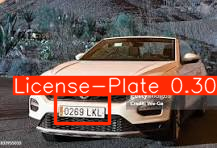

In [ ]:
pred[0].plot()

In [ ]:
model.predict("/content/WhatsApp Video 2026-09-29 at 9.26.28 AM.mp4")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/635) /content/WhatsApp Video 2026-09-29 at 9.26.28 AM.mp4: 384x640 1 License-Plate, 131.5ms
video 1/1 (frame 2/635) /content/WhatsApp Video 2026-09-29 at 9.26.28 AM.mp4: 384x640 1 License-Plate, 20.9ms
video 1/1 (frame 3/635) /content/WhatsApp Video 2026-09-29 at 9.26.28 AM.mp4: 384x640 2 License-Plates, 21.8ms
video 1/1 (frame 4/635) /content/WhatsApp Video 2026-09-29 at 9.26.28 AM.mp4: 384x640 (no detections), 21.6ms
video 1/1 (frame 

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'License-Plate'}
 obb: None
 orig_img: array([[[111,  79,  58],
         [111,  79,  58],
         [118,  78,  58],
         ...,
         [243, 243, 243],
         [243, 243, 243],
         [243, 243, 243]],
 
        [[111,  79,  58],
         [111,  79,  58],
         [118,  78,  58],
         ...,
         [243, 243, 243],
         [243, 243, 243],
         [243, 243, 243]],
 
        [[105,  80,  58],
         [105,  80,  58],
         [111,  79,  58],
         ...,
         [243, 243, 243],
         [243, 243, 243],
         [243, 243, 243]],
 
        ...,
 
        [[112, 113, 118],
         [112, 113, 118],
         [112, 113, 118],
         ...,
         [100,  99, 101],
         [100,  99, 101],
         [101, 100, 102]],
 
        [[113, 114, 119],
         [113, 114, 119],
         [111, 112, 117],
         ...

In [ ]:
from IPython import display
display.Video("/content/WhatsApp Video 2026-09-29 at 9.26.28 AM.mp4",embed =True)

In [ ]:
import cv2

model = YOLO("/content/best.pt")

video_path = "/content/WhatsApp Video 2026-09-29 at 9.26.28 AM.mp4"

cap = cv2.VideoCapture(video_path)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

writer = cv2.VideoWriter("/content/output_raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    results = model.predict(frame, conf=0.25, imgsz=960, verbose=False)
    writer.write(results[0].plot())

cap.release()
writer.release()

!ffmpeg -y -loglevel error -i /content/output_raw.mp4 -vcodec libx264 /content/output.mp4
display.Video("/content/output.mp4", embed=True)

In [ ]:
import gradio as gr
import cv2
import subprocess
from ultralytics import YOLO

model = YOLO("/content/best.pt")

def predict_video(video_path, conf, imgsz):
    cap = cv2.VideoCapture(video_path)
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    raw_path = "/content/gradio_raw.mp4"
    out_path = "/content/gradio_output.mp4"

    writer = cv2.VideoWriter(raw_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        results = model.predict(frame, conf=conf, imgsz=int(imgsz), verbose=False)
        writer.write(results[0].plot())

    cap.release()
    writer.release()

    # browser mein chalne ke liye h264 mein convert
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", raw_path,
         "-vcodec", "libx264", out_path]
    )
    return out_path

demo = gr.Interface(
    fn=predict_video,
    inputs=[
        gr.Video(label="Video upload karein"),
        gr.Slider(0.05, 0.9, value=0.25, step=0.05, label="Confidence"),
        gr.Dropdown([640, 960, 1280], value=640, label="Image size"),
    ],
    outputs=gr.Video(label="Result"),
    title="Number Plate Detection",
)

demo.launch(debug=True)